In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

train = pd.read_csv("Bike_Sharing_Day57_Analysis.csv")

print("Dataset loaded successfully!")
print("Shape:", train.shape)
train.head()

Saving Bike_Sharing_Day57_Analysis.csv to Bike_Sharing_Day57_Analysis.csv
Dataset loaded successfully!
Shape: (10886, 21)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,...,count,year,month,day,hour,weekday,temp_group,humidity_group,windspeed_group,demand_level
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,...,16,2011,1,1,0,5,0-10°C,80-100%,0-10,Low Demand
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,...,40,2011,1,1,1,5,0-10°C,60-80%,0-10,Low Demand
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,...,32,2011,1,1,2,5,0-10°C,60-80%,0-10,Low Demand
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,...,13,2011,1,1,3,5,0-10°C,60-80%,0-10,Low Demand
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,...,1,2011,1,1,4,5,0-10°C,60-80%,0-10,Low Demand


In [2]:
monthly_demand = train.groupby("month")["count"].agg(
    ["mean", "sum", "min", "max"]
)

monthly_demand.columns = [
    "Average Rentals",
    "Total Rentals",
    "Minimum Rentals",
    "Maximum Rentals"
]

monthly_demand.round(2)

,Average Rentals,Total Rentals,Minimum Rentals,Maximum Rentals
month,,,,
1,90.37,79884,1,512
2,110.00,99113,1,539
3,148.17,133501,1,801
4,184.16,167402,1,822
5,219.46,200147,1,873
6,242.03,220733,1,869
7,235.33,214617,1,872
8,234.12,213516,1,897
9,233.81,212529,1,977


In [3]:
monthly_year_demand = train.pivot_table(
    index="month",
    columns="year",
    values="count",
    aggfunc="mean"
)

monthly_year_demand.round(2)

year,2011,2012
month,,
1,54.65,124.35
2,73.64,145.65
3,86.85,208.28
4,111.03,257.46
5,174.81,264.11
6,196.88,287.19
7,203.61,267.04
8,182.67,285.57
9,174.62,292.60


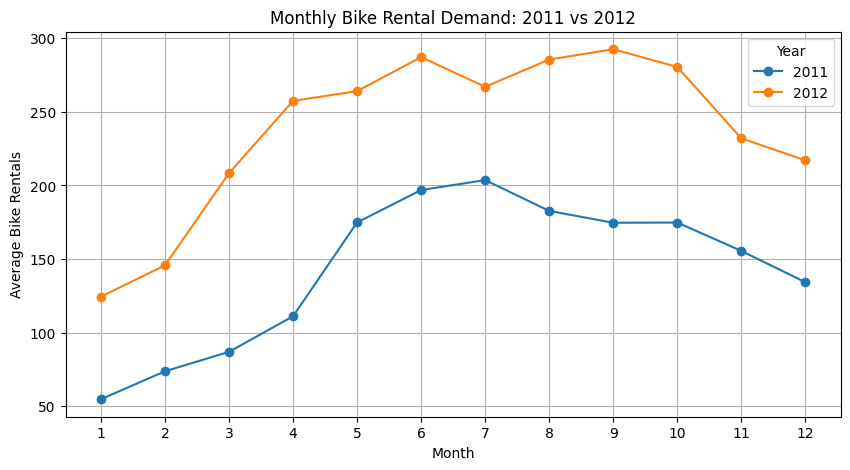

In [4]:
import matplotlib.pyplot as plt

monthly_year_demand.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Bike Rental Demand: 2011 vs 2012")
plt.xlabel("Month")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend(title="Year")
plt.show()

In [5]:
hourly_workingday = train.pivot_table(
    index="hour",
    columns="workingday",
    values="count",
    aggfunc="mean"
)

hourly_workingday.columns = [
    "Non-Working Day",
    "Working Day"
]

hourly_workingday.round(2)

,Non-Working Day,Working Day
hour,,
0,94.49,36.73
1,71.91,16.00
2,53.75,8.44
3,25.53,4.89
4,8.54,5.36
5,9.37,24.53
6,19.99,102.58
7,47.27,290.69
8,112.26,479.95


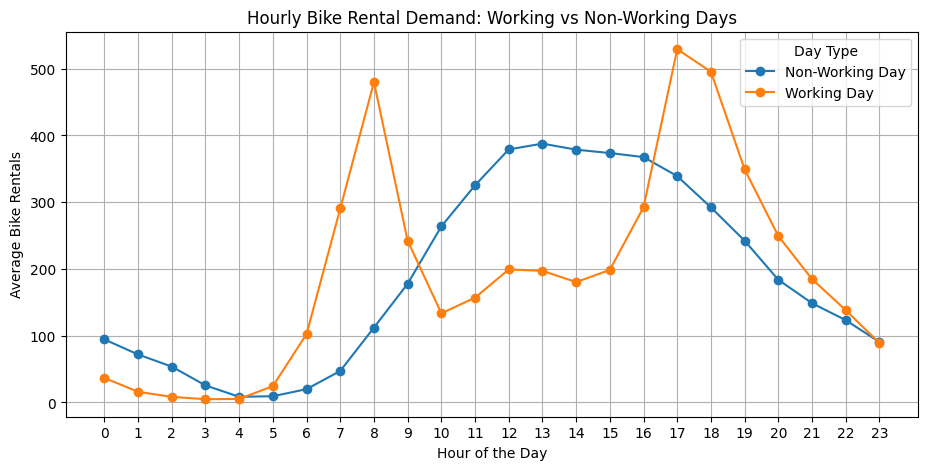

In [6]:
hourly_workingday.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

plt.title("Hourly Bike Rental Demand: Working vs Non-Working Days")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend(title="Day Type")
plt.show()

In [7]:
temp_demand = train.groupby(
    "temp_group",
    observed=False
)["count"].agg(["mean", "count"])

temp_demand.columns = ["Average Rentals", "Records"]

temp_demand.round(2)

,Average Rentals,Records
temp_group,,
0-10°C,73.19,1259
10-20°C,150.47,4049
20-30°C,223.41,4334
30-40°C,334.31,1243
40°C+,294.00,1


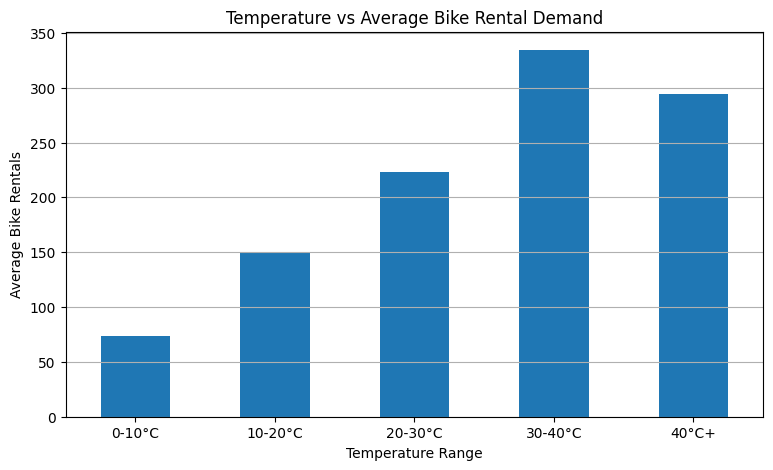

In [8]:
temp_demand["Average Rentals"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Temperature vs Average Bike Rental Demand")
plt.xlabel("Temperature Range")
plt.ylabel("Average Bike Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [9]:
humidity_demand = train.groupby(
    "humidity_group",
    observed=False
)["count"].agg(["mean", "count"])

humidity_demand.columns = ["Average Rentals", "Records"]

humidity_demand.round(2)

,Average Rentals,Records
humidity_group,,
0-20%,180.38,78
20-40%,290.65,1560
40-60%,220.54,3564
60-80%,171.28,3382
80-100%,109.78,2302


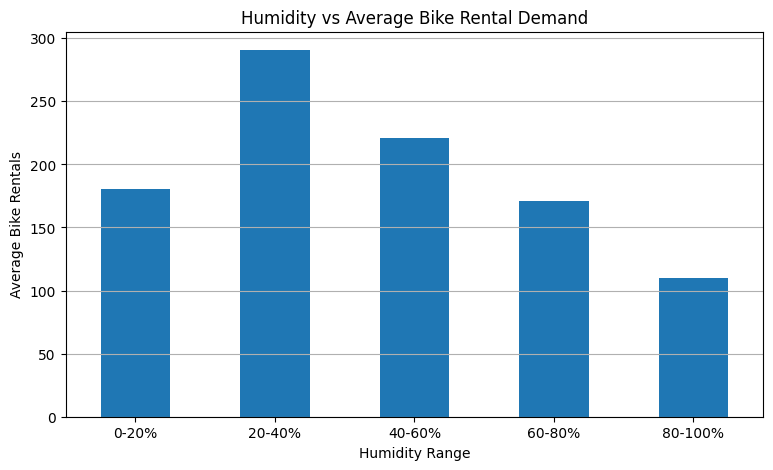

In [10]:
humidity_demand["Average Rentals"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Humidity vs Average Bike Rental Demand")
plt.xlabel("Humidity Range")
plt.ylabel("Average Bike Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [11]:
windspeed_demand = train.groupby(
    "windspeed_group",
    observed=False
)["count"].agg(["mean", "count"])

windspeed_demand.columns = ["Average Rentals", "Records"]

windspeed_demand.round(2)

,Average Rentals,Records
windspeed_group,,
0-10,164.28,4339
10-20,210.29,5052
20-30,209.64,1068
30-40,206.43,387
40-60,161.88,40


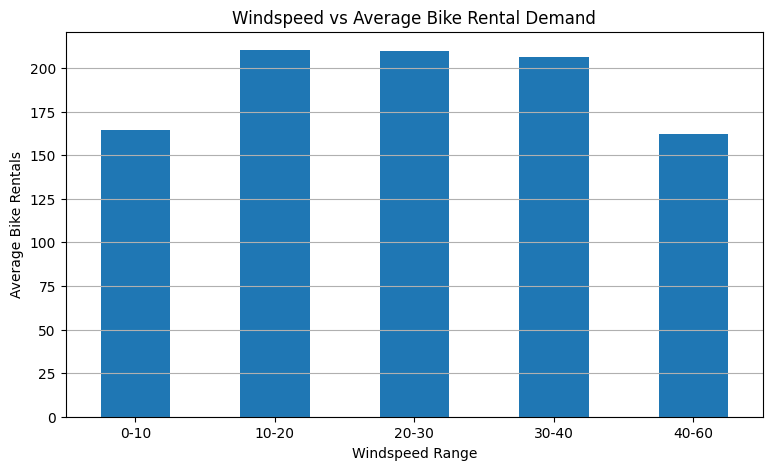

In [12]:
windspeed_demand["Average Rentals"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Windspeed vs Average Bike Rental Demand")
plt.xlabel("Windspeed Range")
plt.ylabel("Average Bike Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [13]:
weekday_demand = train.groupby(
    "weekday"
)["count"].agg(["mean", "sum", "count"])

weekday_demand.columns = [
    "Average Rentals",
    "Total Rentals",
    "Records"
]

weekday_demand.round(2)

,Average Rentals,Total Rentals,Records
weekday,,,
0,190.39,295296,1551
1,189.72,291985,1539
2,188.41,292226,1551
3,197.30,306401,1553
4,197.84,302504,1529
5,196.67,311518,1584
6,180.84,285546,1579


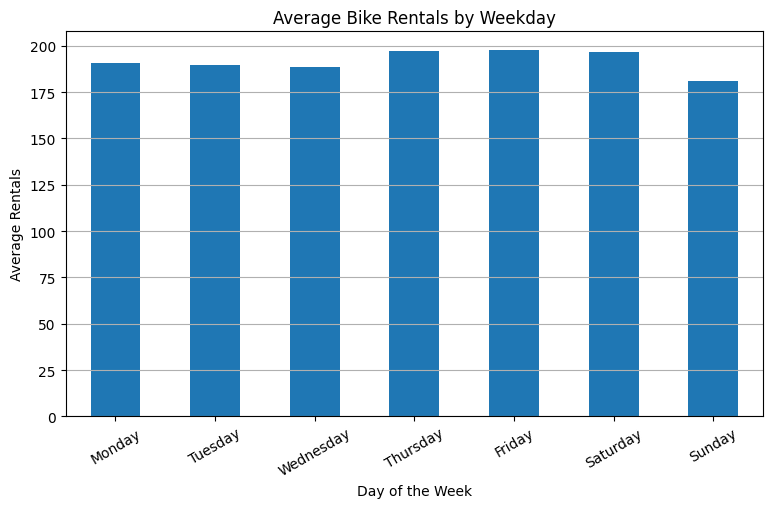

In [14]:
weekday_demand["Average Rentals"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Rentals")
plt.xticks(
    ticks=range(7),
    labels=["Monday", "Tuesday", "Wednesday",
            "Thursday", "Friday", "Saturday", "Sunday"],
    rotation=30
)
plt.grid(axis="y")
plt.show()

In [15]:
season_weather_demand = train.pivot_table(
    index="season",
    columns="weather",
    values="count",
    aggfunc="mean"
)

season_weather_demand.round(2)

weather,1,2,3,4
season,,,,
1,126.78,106.86,61.23,164.0
2,236.73,189.52,123.91,NaN
3,243.58,230.77,156.58,NaN
4,209.51,194.78,134.47,NaN


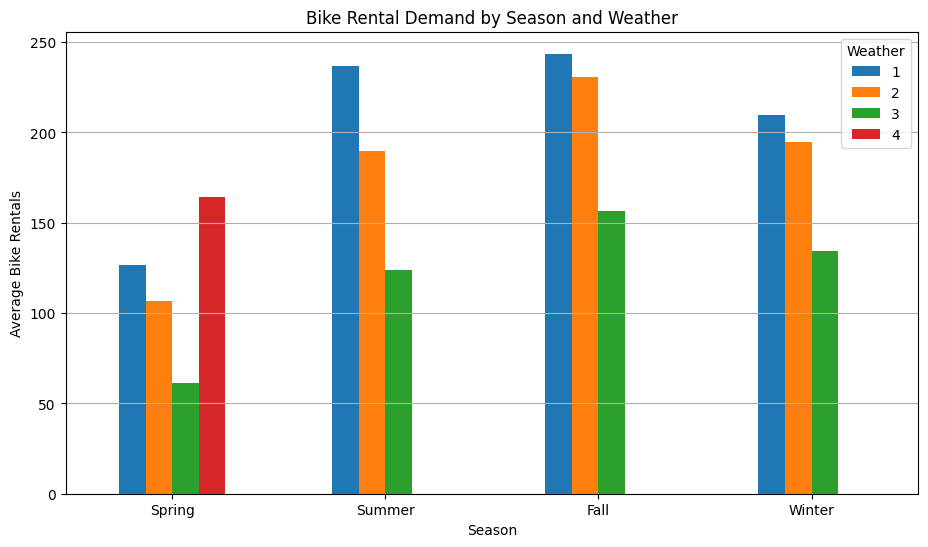

In [16]:
season_weather_demand.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Bike Rental Demand by Season and Weather")
plt.xlabel("Season")
plt.ylabel("Average Bike Rentals")
plt.xticks(
    ticks=range(4),
    labels=["Spring", "Summer", "Fall", "Winter"],
    rotation=0
)
plt.legend(title="Weather")
plt.grid(axis="y")
plt.show()

In [17]:
user_type_analysis = train[["casual", "registered"]].agg(
    ["mean", "median", "min", "max", "sum"]
)

user_type_analysis.round(2)

,casual,registered
mean,36.02,155.55
median,17.00,118.00
min,0.00,0.00
max,367.00,886.00
sum,392135.00,1693341.00


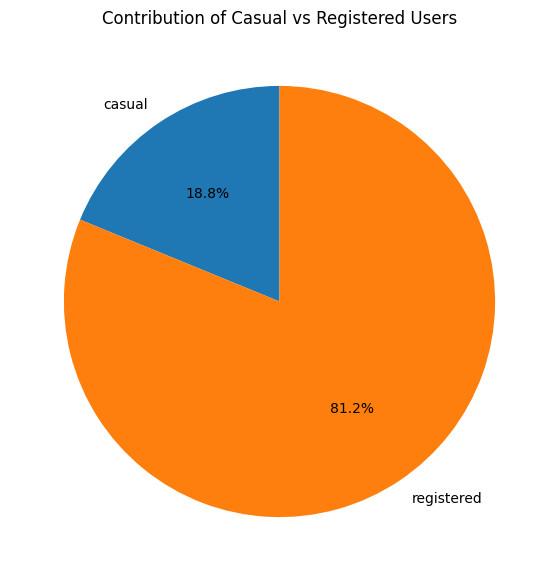

In [18]:
user_totals = train[["casual", "registered"]].sum()

user_totals.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    startangle=90
)

plt.title("Contribution of Casual vs Registered Users")
plt.ylabel("")
plt.show()

In [19]:
hourly_user_analysis = train.groupby("hour")[
    ["casual", "registered"]
].mean()

hourly_user_analysis.round(2)

,casual,registered
hour,,
0,10.31,44.83
1,6.51,27.35
2,4.82,18.08
3,2.68,9.08
4,1.26,5.14
5,1.46,18.31
6,4.15,72.11
7,10.91,202.20
8,21.54,341.23


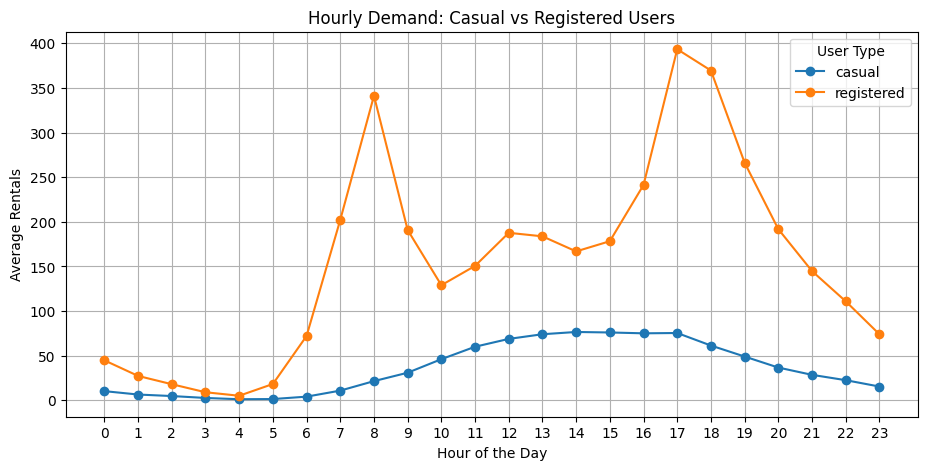

In [20]:
hourly_user_analysis.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

plt.title("Hourly Demand: Casual vs Registered Users")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.legend(title="User Type")
plt.grid(True)
plt.show()

In [21]:
train.to_csv("Bike_Sharing_Day58_Advanced_EDA.csv", index=False)